# Đánh giá baseline và giải thích cạnh — Đức + Kha

**T03 / T06 / phần rà soát T09 — Nhóm 09, C.10.** Không gồm slide.

Kha: Random, nearest-first, agreement. Đức: fidelity xóa/giữ và ground truth.
Dùng điểm T05 của Thiện/Khôi, dữ liệu/checkpoint T01. Không huấn luyện lại GCN hoặc explainer.

**Hai chế độ:** mặc định đọc kết quả thật đã bàn giao; đặt `RUN_EVALUATION = True` để chạy lại predictor trên máy có đúng các `.pt`. Kết quả đọc lại không được nhận là lượt chạy mới.


## 1. File nào làm gì, vì sao có nó?

| File | Vai trò |
|---|---|
| Notebook này | Điều phối chạy, trình bày và kiểm tra kết quả từng phần |
| `src/sna/evaluation/core.py` | Một quy tắc dùng chung cho chọn cạnh, baseline và metrics |
| `src/sna/evaluation/runner.py` | Kiểm tra dữ liệu và chạy các node/k/repeat, xuất CSV |
| `src/sna/evaluation/handover.py` | Sinh bảng T06 trong docs và cập nhật vùng kết quả README |
| `results/` | Kết quả thực, bao gồm cấu hình/hash, metrics, agreement, runtime, lỗi và hình |

Module và notebook T05 gốc giữ nguyên. Bộ đánh giá mới dùng `sna.evaluation`, không gọi baseline/metrics legacy.


In [13]:
from pathlib import Path
import sys, json
from argparse import Namespace

ROOT = Path.cwd().resolve()
while not (ROOT / 'src' / 'sna').exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'sna').exists():
    raise RuntimeError('Hãy mở notebook bên trong thư mục clone IS353_C10-clean.')
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
from sna.evaluation.runner import run, sha256
from sna.evaluation.core import baseline_scores, rank_edges, agreement

NB_DIR = ROOT / 'notebooks' / '05_duc_kha_evaluation'
RESULTS = NB_DIR / 'results'
SCORES = ROOT / 'notebooks' / '01_midterm' / 'edge_scores.csv'
DATA_ROOT = ROOT / 'data'
RUN_EVALUATION = True  # True: tính lại trên data/checkpoint thật; False: xem kết quả bàn giao
UPDATE_DOCS = False     # Chỉ bật sau khi đã rà soát kết quả mới
print('Python:', sys.executable)
print('Repo:', ROOT)
print('Chế độ:', 'CHẠY LẠI PREDICTOR' if RUN_EVALUATION else 'ĐỌC KẾT QUẢ ĐÃ BÀN GIAO')


Python: d:\Projects\IS353_C10-clean\.venv\Scripts\python.exe
Repo: D:\Projects\IS353_C10-clean
Chế độ: CHẠY LẠI PREDICTOR


## 2. Quy ước baseline và metrics

- Random: điểm thô bằng 0; hoán vị đều theo seed để phá hòa rồi lấy top-k.
- Nearest-first: với cạnh (u,w), node đích v, điểm `-min(d(u,v), d(w,v))`; phá hòa riêng, không cộng nhiễu vào điểm AUC.
- Một thứ tự được dùng cho mọi k trong repeat. `k_eff = min(k, số candidate)`.
- Cạnh vô hướng được chọn theo cặp, xóa/giữ cả hai chiều. Đặc trưng giữ nguyên; self-loop mô hình vẫn hoạt động.
- Drop = p(gốc) − p(xóa); Inv = p(gốc) − p(giữ). Không cắt số âm.
- AUROC/AP dùng điểm thô; AP là Average Precision, khác PR-AUC hình thang của bảng cũ.
- Kendall tau-b của điểm hằng, AUROC chỉ một lớp, recall không có positive: NaN kèm lý do.

Ví dụ nhỏ dưới đây minh họa giao thức, **không phải dữ liệu thực nghiệm**.


In [14]:
pairs = [(0, 1), (1, 2), (2, 3), (1, 3)]
example = pd.DataFrame(pairs, columns=['u', 'v'])
for method in ['random', 'nearest_first']:
    scores = baseline_scores(pairs, node_id=0, method=method)
    order = rank_edges(scores, seed=42)
    example[method + '_raw_score'] = scores
    rank = np.empty(len(order), dtype=int)
    rank[order] = np.arange(1, len(order) + 1)
    example[method + '_rank'] = rank
display(example)


,u,v,random_raw_score,random_rank,nearest_first_raw_score,nearest_first_rank
0,0,1,0.0,4,0.0,1
1,1,2,0.0,3,-1.0,3
2,2,3,0.0,2,-2.0,4
3,1,3,0.0,1,-1.0,2


## 3. Kiểm toán CSV T05

Kiểm tra 20 node đầu tiên trong val_nodes.json mỗi dataset; không âm thầm lấy giao node.
Kiểm tra đủ ba phương pháp, cùng lớp đích và ánh xạ edge ID/cặp cạnh, không trùng run/cạnh.
Audit-only chưa mở `.pt`, chưa xác minh predictor/val_mask thực. File kiểm toán ở `audit_checks/`, không đè kết quả đầy đủ.


In [15]:
audit_config = Namespace(
    scores=SCORES, data_root=DATA_ROOT, output=NB_DIR / 'audit_checks',
    datasets=['bashapes', 'cora'], nodes_per_dataset=20,
    budgets=[1, 3, 5, 10], seeds=[0, 1, 2, 3, 4], device='cpu', audit_only=True)
rc = run(audit_config)
if rc:
    display(pd.read_csv(audit_config.output / 'errors.csv'))
    raise RuntimeError('Audit CSV thất bại; cần sửa đầu vào trước.')
display(pd.read_csv(audit_config.output / 'dataset_stats.csv'))


audit_passed: D:\Projects\IS353_C10-clean\notebooks\05_duc_kha_evaluation\audit_checks
Audit rows=120, metric rows=0, errors=0


,dataset,method,n_nodes,edge_rows,mean_candidate_edges
0,bashapes,saliency,20,3473,173.65
1,bashapes,gnnexplainer,20,3473,173.65
2,bashapes,pgexplainer,20,3473,173.65
3,cora,saliency,20,703,35.15
4,cora,gnnexplainer,20,703,35.15
5,cora,pgexplainer,20,703,35.15


## 4. Chạy đầy đủ hoặc đọc kết quả bàn giao

Khi bật `RUN_EVALUATION`, cần `data.pt`, `gcn_ckpt.pt`, `config.json`, `val_nodes.json` trong cả `data/bashapes/` và `data/cora/`.
Sử dụng đúng bộ T05; không thay checkpoint chỉ để làm kết quả đẹp hơn.

Chạy CPU trên 40 node, k=1/3/5/10 và 5 repeat baseline. Không chạy lại explainer; kết quả mới ghi vào `results/`.


In [16]:
if RUN_EVALUATION:
    required = [DATA_ROOT / ds / name for ds in ['bashapes', 'cora']
                for name in ['data.pt', 'gcn_ckpt.pt', 'config.json', 'val_nodes.json']]
    missing = [str(p.relative_to(ROOT)) for p in required if not p.exists()]
    if missing:
        raise FileNotFoundError('Thiếu file T01/T05: ' + ', '.join(missing))
    config = Namespace(scores=SCORES, data_root=DATA_ROOT, output=RESULTS,
                       datasets=['bashapes', 'cora'], nodes_per_dataset=20,
                       budgets=[1, 3, 5, 10], seeds=[0, 1, 2, 3, 4],
                       device='cpu', audit_only=False)
    rc = run(config)
    if rc:
        display(pd.read_csv(RESULTS / 'errors.csv'))
        raise RuntimeError('Có lỗi đánh giá: chưa cập nhật docs/README.')
else:
    print('Đọc nguyên kết quả thật đã bàn giao từ máy Kha; không chạy predictor mới.')

manifest = json.loads((RESULTS / 'manifest.json').read_text(encoding='utf-8'))
if manifest['mode'] != 'full' or manifest['status'] != 'completed':
    raise RuntimeError('results/ chưa có lượt full completed.')
import hashlib
source_bytes = SCORES.read_bytes()
lf_bytes = source_bytes.replace(b'\r\n', b'\n')
compatible_hashes = {hashlib.sha256(source_bytes).hexdigest(),
                     hashlib.sha256(lf_bytes).hexdigest(),
                     hashlib.sha256(lf_bytes.replace(b'\n', b'\r\n')).hexdigest()}
if manifest['source_scores_sha256'] not in compatible_hashes:
    raise RuntimeError('CSV T05 khác nguồn kết quả sau khi kiểm tra cả LF/CRLF; cần đối chiếu/chạy lại.')
if manifest['source_scores_sha256'] != sha256(SCORES):
    print('Hash byte khác do LF/CRLF Windows/Linux; nội dung nguồn khớp sau chuẩn hóa xuống dòng.')
print('Trạng thái:', manifest['status'])
print('Node tính được:', manifest['scored_nodes'])
print('Lỗi:', manifest['error_count'])


completed: D:\Projects\IS353_C10-clean\notebooks\05_duc_kha_evaluation\results
Audit rows=120, metric rows=2080, errors=0
Trạng thái: completed
Node tính được: {'bashapes': 20, 'cora': 20}
Lỗi: 0


## 5. Kiểm tra kết quả và cách tổng hợp

2.080 dòng = 3 explainer × 40 node × 4 k + 2 baseline × 5 repeat × 40 node × 4 k.
Baseline được trung bình trong node trước, sau đó tính mean và SD mẫu giữa node; repeat không phải mẫu độc lập.


In [17]:
metrics = pd.read_csv(RESULTS / 'metrics.csv')
summary = pd.read_csv(RESULTS / 'summary.csv')
agreements = pd.read_csv(RESULTS / 'agreement.csv')
agreement_summary = pd.read_csv(RESULTS / 'agreement_summary.csv')
audit = pd.read_csv(RESULTS / 'audit.csv')
errors = pd.read_csv(RESULTS / 'errors.csv')
assert len(metrics) == 2080 and len(agreements) == 6080 and len(audit) == 120
assert metrics.status.eq('success').all() and len(errors) == 0
assert audit.graph_verified.all()
assert np.allclose(metrics.orig_prob - metrics.delete_prob, metrics.fid_drop)
assert np.allclose(metrics.orig_prob - metrics.keep_prob, metrics.fid_inv)
assert metrics.k_eff.eq(np.minimum(metrics.budget, metrics.n_candidates)).all()
for metric in ['fid_drop', 'fid_inv', 'roc_auc', 'average_precision', 'precision', 'recall']:
    node_values = metrics.groupby(['dataset', 'method', 'budget', 'node_id'])[metric].mean()
    actual = node_values.groupby(['dataset', 'method', 'budget']).agg(['mean', 'std', 'count'])
    stored = summary[summary.metric == metric].set_index(['dataset', 'method', 'budget']).loc[actual.index]
    assert np.allclose(actual['mean'], stored['mean'], equal_nan=True)
    assert np.allclose(actual['std'], stored['std'], equal_nan=True)
    assert actual['count'].eq(stored.n_valid_nodes).all()
print('PASS: số lượng, audit, fidelity, k_eff và toàn bộ mean/SD/số node hợp lệ.')


PASS: số lượng, audit, fidelity, k_eff và toàn bộ mean/SD/số node hợp lệ.


## 6. Bảng kết quả top-5

Fidelity có 20 node/dataset; BA-Shapes AUROC/AP chỉ có 10 node đủ hai lớp. Cora không có ground truth.


In [18]:
top5 = summary[summary.budget == 5]
for ds in ['bashapes', 'cora']:
    print(ds.upper())
    table = top5[(top5.dataset == ds) & top5.metric.isin(['fid_drop', 'fid_inv', 'roc_auc', 'average_precision'])]
    display(table[['method', 'metric', 'mean', 'std', 'n_valid_nodes', 'n_total_nodes']].reset_index(drop=True))


BASHAPES


,method,metric,mean,std,n_valid_nodes,n_total_nodes
0,gnnexplainer,fid_drop,0.308826,0.377052,20,20
1,gnnexplainer,fid_inv,0.211131,0.425904,20,20
2,gnnexplainer,roc_auc,0.739191,0.207790,10,20
3,gnnexplainer,average_precision,0.757003,0.400285,10,20
4,nearest_first,fid_drop,0.372765,0.405976,20,20
5,nearest_first,fid_inv,0.150767,0.263565,20,20
6,nearest_first,roc_auc,0.652537,0.082848,10,20
7,nearest_first,average_precision,0.695194,0.371903,10,20
8,pgexplainer,fid_drop,0.219515,0.321641,20,20
9,pgexplainer,fid_inv,0.324766,0.425778,20,20


CORA


,method,metric,mean,std,n_valid_nodes,n_total_nodes
0,gnnexplainer,fid_drop,0.031603,0.080996,20,20
1,gnnexplainer,fid_inv,-0.050422,0.264510,20,20
2,gnnexplainer,roc_auc,NaN,NaN,0,20
3,gnnexplainer,average_precision,NaN,NaN,0,20
4,nearest_first,fid_drop,0.011352,0.247290,20,20
5,nearest_first,fid_inv,-0.042157,0.094644,20,20
6,nearest_first,roc_auc,NaN,NaN,0,20
7,nearest_first,average_precision,NaN,NaN,0,20
8,pgexplainer,fid_drop,-0.007664,0.074461,20,20
9,pgexplainer,fid_inv,-0.005071,0.255991,20,20


## 7. Agreement giữa explainer

Đọc điểm đã căn chỉnh cùng cặp cạnh; top-k dùng thứ hạng đã lưu.
Kendall trên Random điểm hằng không xác định, không được thay bằng 0.


In [19]:
primary = agreement_summary[
    (agreement_summary.budget == 5) &
    ~agreement_summary.method_a.isin(['random', 'nearest_first']) &
    ~agreement_summary.method_b.isin(['random', 'nearest_first'])]
display(primary[['dataset', 'method_a', 'method_b', 'metric', 'mean', 'std', 'n_valid_nodes']])
ranks = pd.read_csv(RESULTS / 'ranked_edges.csv')
rank_groups = {key: part for key, part in ranks.groupby(['dataset', 'node_id', 'method', 'repeat_seed'])}
for row in agreements.itertuples():
    selected = []
    for method in [row.method_a, row.method_b]:
        keys = [key for key in rank_groups if key[:3] == (row.dataset, row.node_id, method)]
        key = next(key for key in keys if key[3] == row.repeat_seed) if method in ['random', 'nearest_first'] else keys[0]
        part = rank_groups[key]
        chosen = part[part['rank'] <= row.budget]
        selected.append(set(zip(chosen.u, chosen.v)))
    expected = len(selected[0] & selected[1]) / len(selected[0] | selected[1])
    assert np.isclose(expected, row.jaccard)
print('PASS: mọi Jaccard khớp thứ hạng cạnh đã lưu.')


,dataset,method_a,method_b,metric,mean,std,n_valid_nodes
12,bashapes,gnnexplainer,pgexplainer,jaccard,0.380952,0.340594,20
13,bashapes,gnnexplainer,pgexplainer,kendall_tau_b,0.146867,0.240092,18
52,bashapes,saliency,gnnexplainer,jaccard,0.419048,0.397390,20
53,bashapes,saliency,gnnexplainer,kendall_tau_b,-0.038067,0.461477,20
68,bashapes,saliency,pgexplainer,jaccard,0.356349,0.308584,20
69,bashapes,saliency,pgexplainer,kendall_tau_b,-0.056037,0.263464,18
92,cora,gnnexplainer,pgexplainer,jaccard,0.313690,0.363661,20
93,cora,gnnexplainer,pgexplainer,kendall_tau_b,0.101582,0.297424,20
132,cora,saliency,gnnexplainer,jaccard,0.268452,0.350505,20
133,cora,saliency,gnnexplainer,kendall_tau_b,0.015746,0.422658,20


PASS: mọi Jaccard khớp thứ hạng cạnh đã lưu.


## 8. Giá trị âm, metric không xác định, runtime và lỗi

Runtime explainer từng node thiếu trong CSV T05 được giữ là unavailable. Không lấy thời gian chạy fidelity để thay runtime explainer.


In [20]:
ba_nodes = metrics[(metrics.dataset == 'bashapes') & (metrics.method == 'saliency') & (metrics.budget == 5)]
display(ba_nodes[['node_id', 'n_candidates', 'gt_positives', 'roc_auc', 'auc_reason', 'recall_reason']])
print('Dòng Drop âm (gồm repeat/ngân sách):', int((metrics.fid_drop < 0).sum()))
print('Node Cora có dưới 5 cạnh:', metrics[(metrics.dataset == 'cora') & (metrics.method == 'saliency') & (metrics.budget == 5) & (metrics.n_candidates < 5)].node_id.tolist())
display(pd.read_csv(RESULTS / 'runtime_summary.csv'))
print('Số lỗi:', len(errors))


,node_id,n_candidates,gt_positives,roc_auc,auc_reason,recall_reason
2,692,6,6.0,NaN,single_class_or_empty_candidates,NaN
54,697,7,6.0,0.500000,NaN,NaN
106,443,6,6.0,NaN,single_class_or_empty_candidates,NaN
158,650,13,6.0,0.785714,NaN,NaN
210,263,293,2.0,0.919244,NaN,NaN
262,374,6,6.0,NaN,single_class_or_empty_candidates,NaN
314,74,499,0.0,NaN,single_class_or_empty_candidates,no_positive_candidate
366,259,247,0.0,NaN,single_class_or_empty_candidates,no_positive_candidate
418,559,7,6.0,0.000000,NaN,NaN
470,337,7,6.0,0.166667,NaN,NaN


Dòng Drop âm (gồm repeat/ngân sách): 856
Node Cora có dưới 5 cạnh: [528, 233]


,dataset,method,metric,mean,std,n_valid_nodes,n_total_nodes
0,bashapes,gnnexplainer,score_runtime_sec,NaN,NaN,0,20
1,bashapes,gnnexplainer,ranking_runtime_sec,NaN,NaN,0,20
2,bashapes,nearest_first,score_runtime_sec,0.000119,0.000137,20,20
3,bashapes,nearest_first,ranking_runtime_sec,0.000178,0.000037,20,20
4,bashapes,pgexplainer,score_runtime_sec,NaN,NaN,0,20
5,bashapes,pgexplainer,ranking_runtime_sec,NaN,NaN,0,20
6,bashapes,random,score_runtime_sec,0.000005,0.000001,20,20
7,bashapes,random,ranking_runtime_sec,0.000173,0.000026,20,20
8,bashapes,saliency,score_runtime_sec,NaN,NaN,0,20
9,bashapes,saliency,ranking_runtime_sec,NaN,NaN,0,20


Số lỗi: 0


## 9. Biểu đồ từ kết quả chạy

Error bars là SD giữa node. Đường cong không bắt buộc đơn điệu do predictor có phi tuyến và chuẩn hóa cạnh.


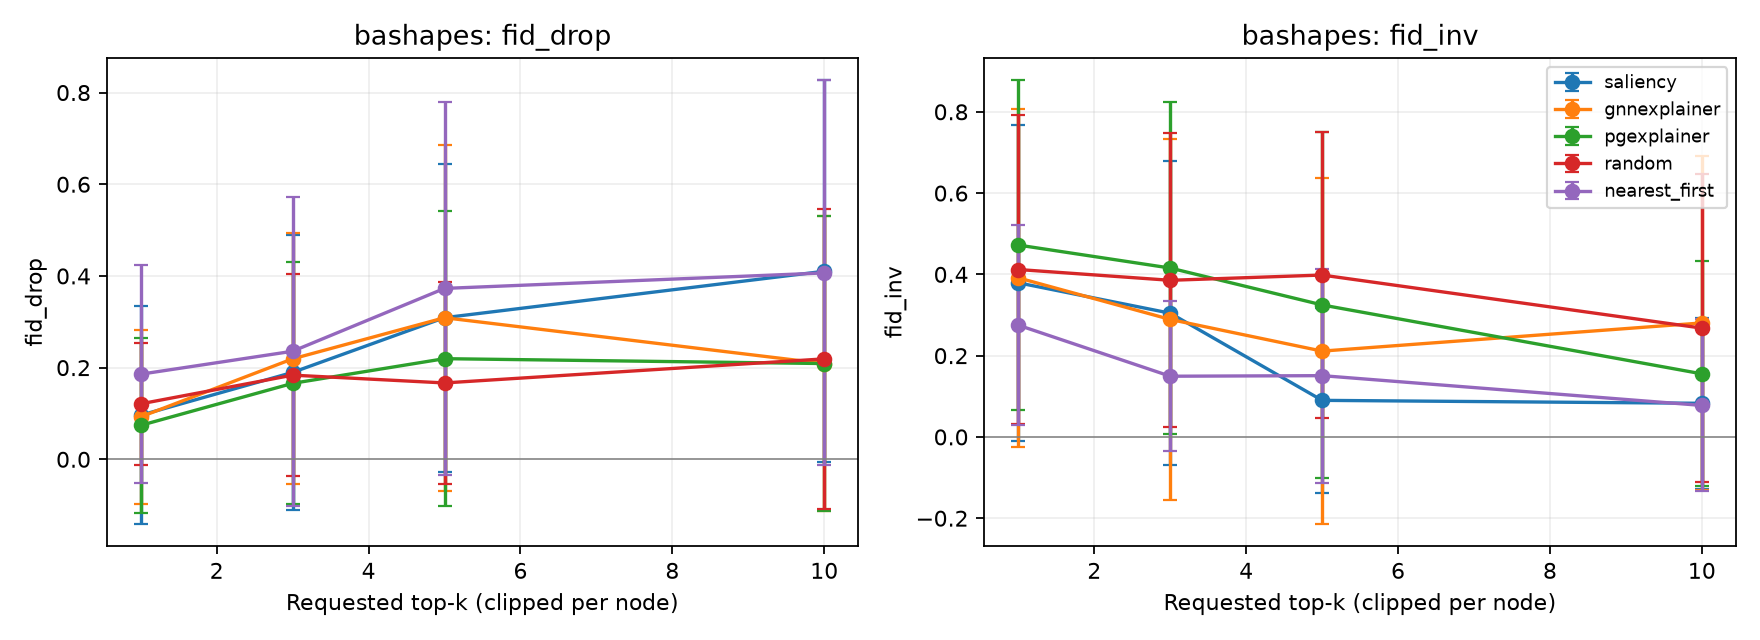

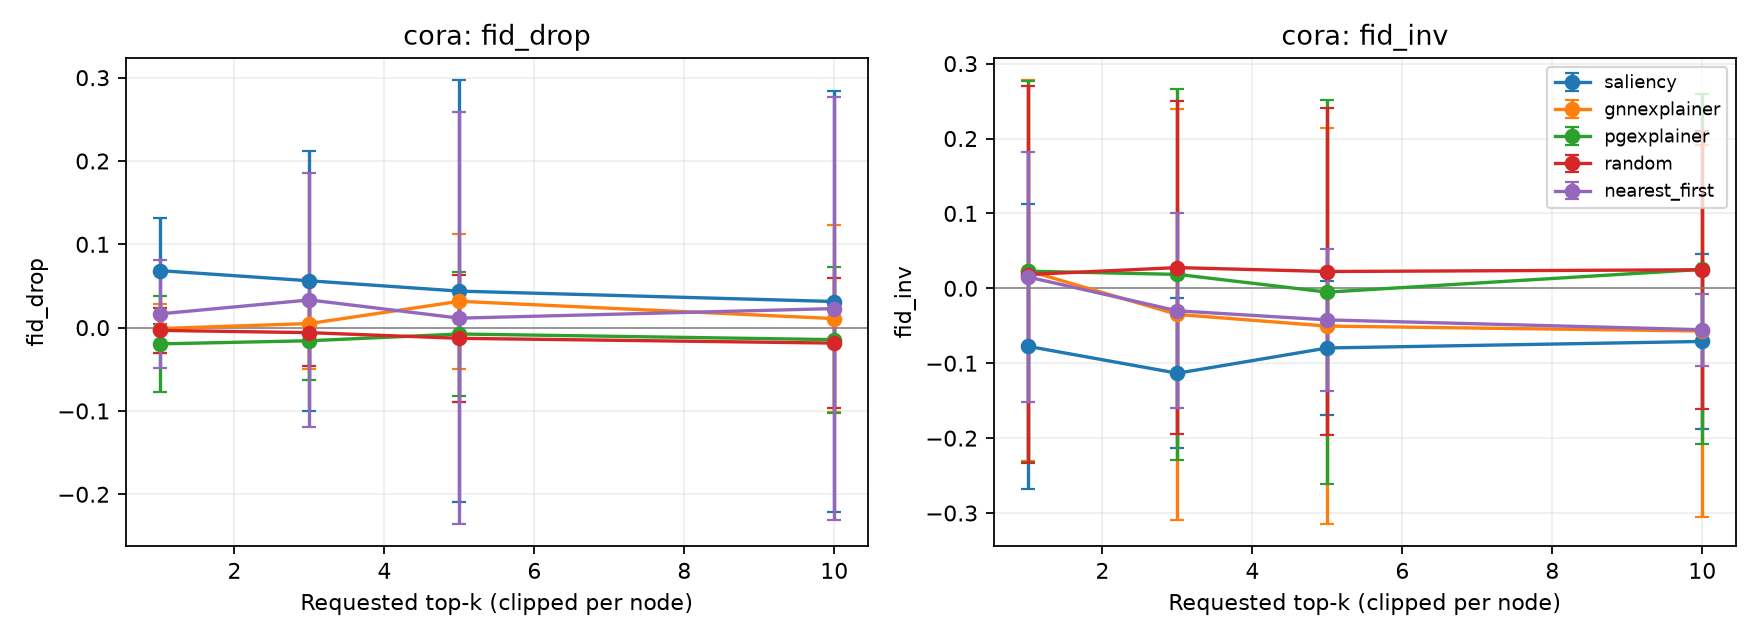

In [21]:
for name in ['bashapes_fidelity.png', 'cora_fidelity.png']:
    display(Image(filename=str(RESULTS / name)))


## 10. Nhận xét và giới hạn

Không có một phương pháp luôn tốt nhất trên mọi metric. Baseline nearest-first cần được đối chiếu; motif overlap khác fidelity.
Mẫu nhỏ, một checkpoint/dataset và lượt explainer T05 có sẵn không đủ để tuyên bố vượt trội tổng quát.
CSV nguồn thiếu hash checkpoint lúc tạo scores và runtime explainer từng node; cần nhóm T05 bổ sung, không tự điền.


In [22]:
report = (RESULTS / 'report.md').read_text(encoding='utf-8')
start = report.find('## Nhận xét sơ bộ')
display(Markdown(report[start:] if start >= 0 else report))


## Nhận xét sơ bộ tự sinh

- bashapes, top-5: nearest_first có trung bình Fidelity Drop cao nhất trong các phương pháp tính được (0.3728; 20 node). Đây là mô tả mẫu, chưa phải kết luận vượt trội có ý nghĩa thống kê.
- bashapes, top-5: pgexplainer có trung bình motif AUROC cao nhất trong các phương pháp tính được (0.8000; 10 node). Đây là mô tả mẫu, chưa phải kết luận vượt trội có ý nghĩa thống kê.
- cora, top-5: saliency có trung bình Fidelity Drop cao nhất trong các phương pháp tính được (0.0438; 20 node). Đây là mô tả mẫu, chưa phải kết luận vượt trội có ý nghĩa thống kê.
- Jaccard@5 trung bình giữa các explainer nằm trong khoảng 0.2685–0.4190; đồng thuận không đồng nghĩa với đúng ground truth.
- Có 856 dòng Fidelity Drop âm (bao gồm các repeat/ngân sách); cần xem node cụ thể trong metrics.csv, không loại bỏ âm thầm.

## Giới hạn và phần còn thiếu

- Số lỗi/đầu vào thiếu: 0; chi tiết errors.csv. Node thành công: {'bashapes': 20, 'cora': 20}.
- Một checkpoint mỗi dataset, một lượt explainer T05; repeat baseline không thay thế nhiều seed GNN/explainer.
- Top-k có thể chiếm tỷ lệ rất khác nhau giữa node; xem k_eff và n_candidates.
- Thiếu hash checkpoint và thời gian trong bàn giao T05 cần được nhóm tạo scores xác nhận/bổ sung.
- Hướng tiếp: khóa giao thức, bổ sung log thời gian/provenance, tăng node và seed trước khi suy rộng.


## 11. Cập nhật docs và README (tùy chọn)

Sau khi đã xem kết quả, bật `UPDATE_DOCS = True` ở ô cấu hình và chạy ô này.
Chỉ thay vùng bảng kết quả có marker trong README; giữ nguyên bảng T05 gốc trong docs và các notebook/thuật toán gốc.
Khi thay tập node, ngân sách hoặc dataset ngoài cấu hình hiện tại, phải rà soát lại các nhận xét và số node trong docs.


In [23]:
if UPDATE_DOCS:
    from sna.evaluation.handover import build_handover
    path = build_handover(ROOT, RESULTS)
    print('Đã cập nhật:', path.relative_to(ROOT), 'và bảng kết quả README.md')
else:
    print('Giữ nguyên docs/README. Bật UPDATE_DOCS sau khi rà soát nếu cần cập nhật.')


Giữ nguyên docs/README. Bật UPDATE_DOCS sau khi rà soát nếu cần cập nhật.
